# 13 — Kết quả đo thật: gradient theo vai trò, PH và đối chứng hiệu chỉnh điểm

**Phạm vi:** Diginetica, GRU4Rec/NARM/SASRec, seeds 2024/2025; thiên lệch độ phổ biến và hình học embedding.

- PH-guided role gradient: 22 lượt pilot, mỗi lượt 4.096 train / 8.192 validation examples, 2 epoch fine-tune.
  Không cải thiện rare hit so với CE ở cả sáu cặp model–seed. Không dùng test cho pilot.
- Đối chứng chấm điểm: chọn hệ số trên toàn bộ validation, lưu policy khóa rồi mới đọc kết quả test.
  Rare Recall tăng 1,877–3,142 điểm phần trăm, thêm 49–82 rare hit/run trên 2.610 query rare.
  Recall tổng giảm 0,145–0,405 điểm phần trăm trên 40.001 query test/run.
- Đối chứng này có tiền lệ; **không gọi là thuật toán mới hay thành công của PH**.
  Không cần huấn luyện lại hoặc đổi embedding. Có đánh đổi độ chính xác tổng.

Bootstrap ghép cặp theo session có cận dưới rare gain dương ở cả 6 run. CI này không bao gồm biến thiên
do training. SASRec seed 2024 có CI của mức giảm Recall tổng vượt 0,5 pp ở một đầu; giới hạn 0,5 pp
chỉ đạt theo ước lượng điểm trên test, không phải bảo đảm thống kê. Test Diginetica đã được xem trong
các phân tích trước đây; chưa có xác nhận trên dataset độc lập hoặc đo hiệu quả kinh doanh.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'BTL-K03-tong-quan-de-tai.md').exists())
sys.path.insert(0, str(ROOT / 'src'))
ROLE = ROOT / 'results/persistent_homology/role_gradient_report_20261121_v1'
CONTROL = ROOT / 'results/persistent_homology/popularity_calibration_control_20261121_v1'
print(json.loads((ROLE / 'verdict.json').read_text())['status'])
role_results = pd.read_csv(ROLE / 'ranking_effects.csv')
display(role_results.loc[role_results.group.eq('rare'), ['model', 'seed', 'method', 'hits', 'n_queries', 'recall']])


added_value_not_demonstrated


,model,seed,method,hits,n_queries,recall
1,gru4rec,2024,baseline,183,523,0.349904
3,gru4rec,2024,role_input_scale,183,523,0.349904
5,gru4rec,2024,role_tangent,183,523,0.349904
7,gru4rec,2024,ph_h0_h1,183,523,0.349904
9,gru4rec,2024,role_ph,183,523,0.349904
11,gru4rec,2024,untouched,182,523,0.347992
13,gru4rec,2025,baseline,178,515,0.345631
15,gru4rec,2025,role_input_scale,178,515,0.345631
17,gru4rec,2025,role_tangent,178,515,0.345631
19,gru4rec,2025,ph_h0_h1,178,515,0.345631


method                     baseline  popularity_calibration  delta_pp
model   seed target_group                                            
gru4rec 2024 all_warm      0.555536                0.554036 -0.149996
             rare          0.321839                0.353257  3.141762
        2025 all_warm      0.558511                0.556036 -0.247494
             rare          0.333333                0.359004  2.567050
narm    2024 all_warm      0.563161                0.560161 -0.299993
             rare          0.324138                0.353257  2.911877
        2025 all_warm      0.561836                0.560386 -0.144996
             rare          0.330651                0.357471  2.681992
sasrec  2024 all_warm      0.570511                0.566461 -0.404990
             rare          0.365517                0.391954  2.643678
        2025 all_warm      0.575336                0.571911 -0.342491
             rare          0.360153                0.378927  1.877395

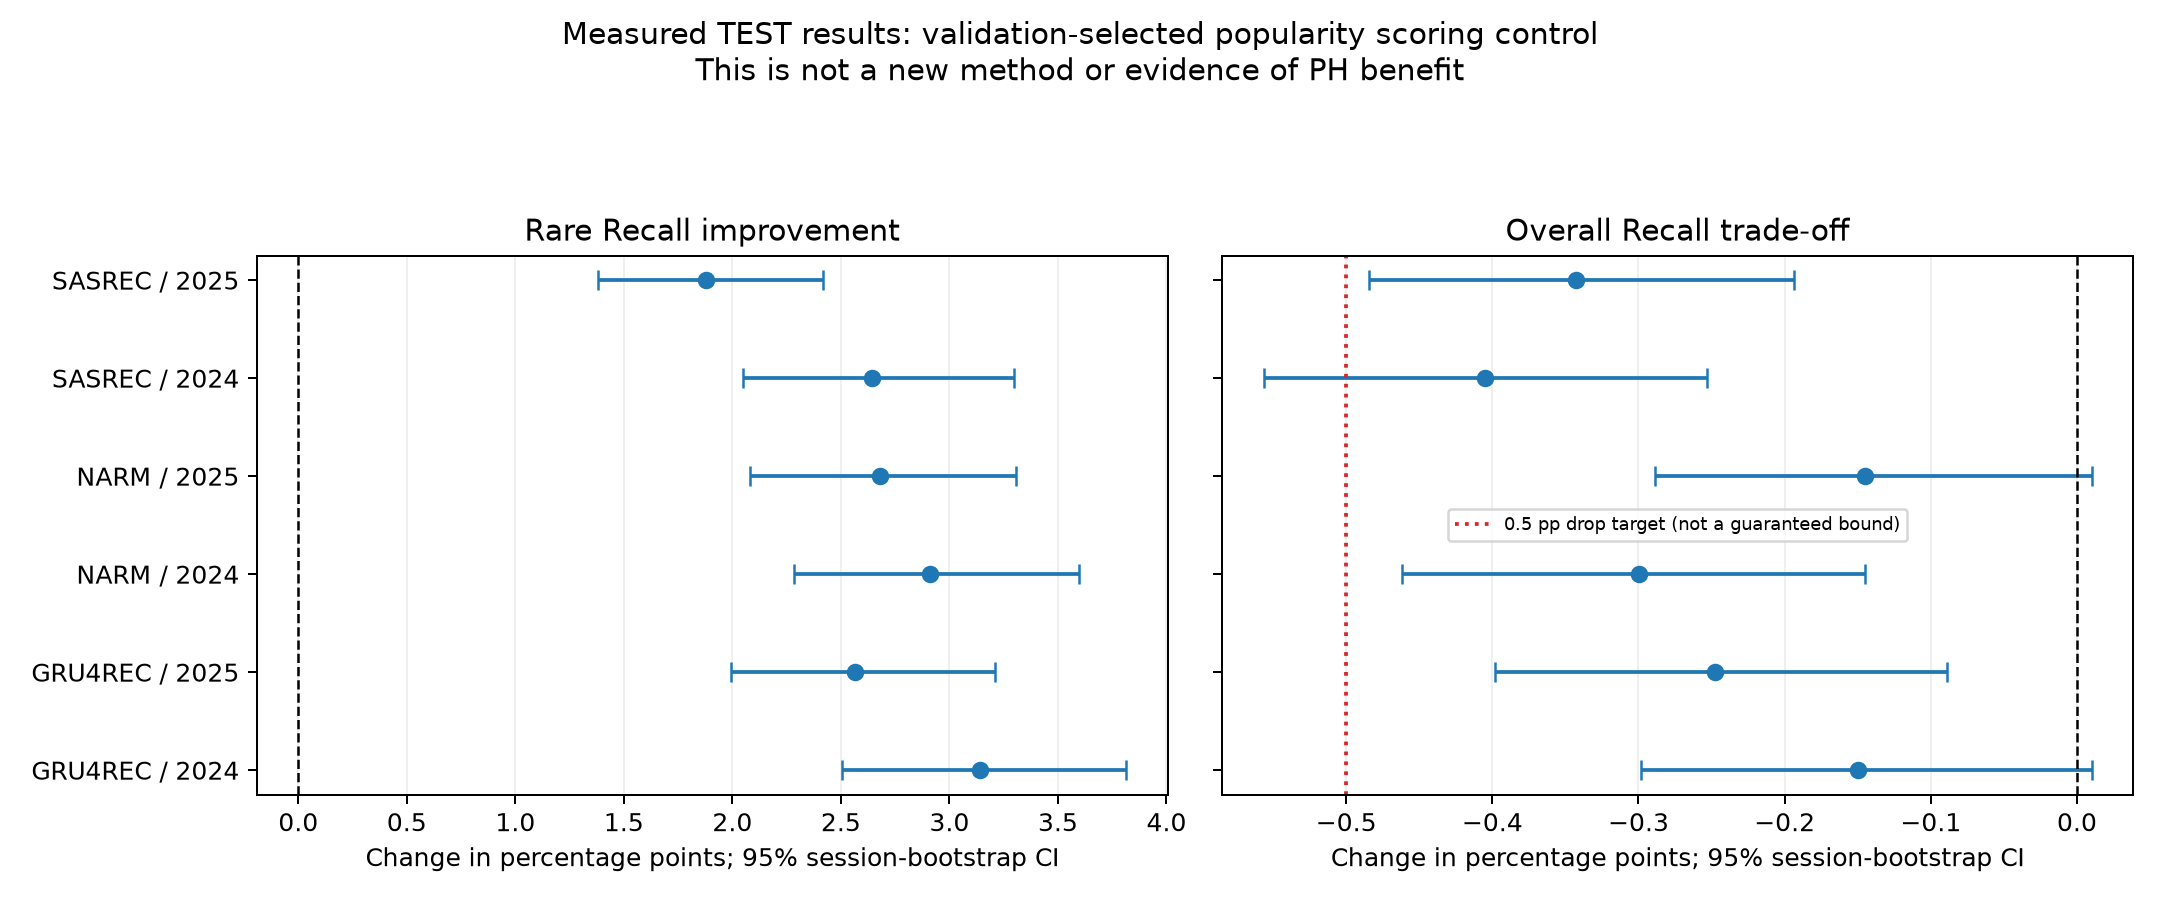

In [2]:
measured = pd.read_csv(CONTROL / 'test_comparison.csv')
table = measured.pivot(index=['model', 'seed', 'target_group'], columns='method', values='recall@20')
table['delta_pp'] = 100 * (table.popularity_calibration - table.baseline)
display(table.loc[table.index.get_level_values('target_group').isin(['rare', 'all_warm'])])
from IPython.display import Image, display
display(Image(filename=str(CONTROL / 'measured_recall_tradeoff.png')))


## Dùng lại cấu hình đã khóa

Module `PopularityScoreCalibrator` chỉ thay điểm xếp hạng; candidate mask vẫn do mô hình gốc thực hiện.
Nó thêm buffer một số thực cho mỗi item. Không thêm tham số cần học. Không tự suy ra doanh thu tăng.
Ví dụ dưới đây chỉ khởi tạo policy; muốn suy luận, áp dụng `calibrator(model.full_sort_logits(...))` rồi top-k.


In [3]:
from btl_k03.score_calibration import PopularityScoreCalibrator
mapping = pd.read_csv(ROOT / 'data/processed/diginetica/item_mapping.csv')
policy = CONTROL / 'sasrec/seed_2024/locked_policy.json'
calibrator = PopularityScoreCalibrator.from_validation_policy(policy, mapping)
print('Locked coefficient:', calibrator.coefficient)
assert calibrator.coefficient == json.loads(policy.read_text())['coefficient']


Locked coefficient: 0.2


## Tái lập

Chạy vào thư mục đầu ra mới, không chỉnh hệ số theo test:

```powershell
python -B scripts/calibrate.py --output results/persistent_homology/calibration_reproduction
```

Code gradient: `src/btl_k03/topology/role_gradients.py`.
Notebook full training đã đóng gói tại `kaggle/role-ph-embedding-study/ph-embedding-study.ipynb`, chưa đưa lên Kaggle.
Thành tựu hiện có là **định lượng được trade-off có thể dùng lại**, đồng thời loại một ứng viên PH chưa đủ hiệu quả.
Muốn tuyên bố đóng góp phương pháp mới, PH phải vượt đối chứng này trong thực nghiệm xác nhận.
